# Take Home Test — Data Science & ML
## Inventory Sell-Through Prediction (`inventory_items.csv`)
**Peserta:** Adnan Anwar Rabbani

> **Cara menjalankan:** taruh `inventory_items.csv` di folder yang sama dengan notebook ini, lalu *Run All*. Notebook ini **berdiri sendiri** (tidak butuh file `.py` lain). Bagian deep learning butuh `tensorflow` (`pip install tensorflow` bila belum ada). Total waktu ±7–10 menit di CPU biasa.

## Tahap 1 — Strategic Analytics & Problem Statement
**Konteks:** Perusahaan e-commerce fashion menyimpan ±490 ribu unit inventori. Unit yang tidak terjual menjadi *dead stock* (modal tertahan, biaya gudang).

**Business problem:** Unit mana yang berisiko tidak terjual, dan faktor apa yang benar-benar memengaruhinya?

**Problem statement (ML):** Klasifikasi biner `is_sold` (1 = unit pernah terjual) memakai hanya informasi yang tersedia saat stok dibuat (kategori, brand, departemen, DC, harga, cost, waktu pembuatan). `sold_at` **tidak** dipakai sebagai fitur (leakage).

**Metrik:** ROC-AUC (utama), PR-AUC, F1/Recall/Precision pada threshold terpilih, log-loss.

## Tahap 2 — Data Understanding & Preprocessing

In [1]:
import warnings, json, time; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid')

# ===== LOAD DATA (ganti path jika file ada di lokasi lain) =====
DATA_PATH = 'inventory_items.csv'
df = pd.read_csv(DATA_PATH)
df['created_at'] = pd.to_datetime(df['created_at'], utc=True, format='ISO8601')
df['sold_at'] = pd.to_datetime(df['sold_at'], utc=True, format='ISO8601')
df = df.drop_duplicates('id')
df['is_sold'] = df['sold_at'].notna().astype(int)   # target: 1 = pernah terjual

print(df.shape)
if len(df) < 490000:
    print('PERINGATAN: data hanya', len(df), 'baris (seharusnya 490.705). File CSV mungkin terpotong / belum selesai di-upload; hasil akan berbeda dari laporan.')
df.head()

(490705, 13)


,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id,is_sold
0,67971,13844,2022-07-02 07:09:20+00:00,2022-07-24 06:33:20+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7,1
1,67972,13844,2023-12-20 03:28:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7,0
2,67973,13844,2023-06-04 02:53:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7,0
3,72863,13844,2021-10-16 22:58:52+00:00,2021-11-22 02:19:52+00:00,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7,1
4,72864,13844,2021-08-07 16:33:00+00:00,NaT,2.76804,Accessories,(ONE) 1 Satin Headband,Funny Girl Designs,6.99,Women,2A3E953A5E3D81E67945BCE5519F84C8,7,0


In [2]:
print(df.dtypes); print(); print('Missing:'); print(df.isna().sum()[lambda s: s>0])
print('created_at:', df.created_at.min(), '->', df.created_at.max()); print('sold_at   :', df.sold_at.min(), '->', df.sold_at.max())
print('Rasio terjual:', round(df.is_sold.mean(),4))

id                                              int64
product_id                                      int64
created_at                        datetime64[us, UTC]
sold_at                           datetime64[us, UTC]
cost                                          float64
product_category                                  str
product_name                                      str
product_brand                                     str
product_retail_price                          float64
product_department                                str
product_sku                                       str
product_distribution_center_id                  int64
is_sold                                         int64
dtype: object

Missing:
sold_at          308946
product_name         29
product_brand       401
dtype: int64
created_at: 2018-11-08 04:14:18+00:00 -> 2024-01-21 03:29:15.939041+00:00
sold_at   : 2019-01-06 02:25:41+00:00 -> 2024-01-21 18:02:23.533893+00:00
Rasio terjual: 0.3704


**Temuan kualitas data**
- `sold_at` kosong = belum terjual (bukan data hilang) → dipakai untuk membuat target `is_sold`.
- `product_name` (29) dan `product_brand` (401) kosong → brand diisi `UNKNOWN`; brand langka (<50 unit) digabung `OTHER`. `product_name` tidak dipakai.
- Tidak ada duplikat `id`.

In [3]:
d = (df.sold_at-df.created_at).dt.total_seconds()/86400
print(d.describe().round(2)); print('Negatif:', (d<0).sum())
print('Terakhir terjual:', df.sold_at.max())

count    181759.00
mean         29.93
std          17.32
min           0.00
25%          14.91
50%          29.92
75%          44.90
max          60.00
dtype: float64
Negatif: 0
Terakhir terjual: 2024-01-21 18:02:23.533893+00:00


**Right-censoring.** Waktu terjual maksimal 60 hari dan data berakhir 2024-01-21. Item yang dibuat setelah **2023-11-22** belum punya 60 hari penuh untuk terjual, sehingga label "tidak terjual" belum final. Item tersebut dibuang dari **pemodelan** (bukan dari EDA).

In [4]:
CENSOR_CUTOFF = pd.Timestamp('2023-11-22', tz='UTC')
m = df[df['created_at'] < CENSOR_CUTOFF].copy()   # data untuk pemodelan
print('Baris pemodelan:', len(m), '| dibuang:', len(df)-len(m), '| rasio terjual:', round(m.is_sold.mean(),4))

Baris pemodelan: 462133 | dibuang: 28572 | rasio terjual: 0.357


**Pipeline fitur.** `FeatureBuilder` membangun fitur dari kolom mentah (waktu `t_days`, sin/cos bulan, hari, log harga/cost, margin, brand→top/OTHER). Semua digabung dalam satu `Pipeline` scikit-learn, sehingga encoder/scaler hanya di-*fit* pada data latih (tanpa leakage) dan kode yang sama dipakai aplikasi Streamlit.

In [5]:
from sklearn.base import BaseEstimator, TransformerMixin
T0 = pd.Timestamp('2018-11-08', tz='UTC')
CAT_COLS = ['product_category','product_department','product_brand','dc']
NUM_COLS = ['t_days','month_sin','month_cos','dow','log_price','log_cost','margin_pct','margin_abs']
RAW = ['created_at','cost','product_category','product_brand','product_retail_price','product_department','product_distribution_center_id']

class FeatureBuilder(BaseEstimator, TransformerMixin):
    """Hanya memakai informasi saat stok dibuat (sold_at TIDAK dipakai). Brand langka -> 'OTHER'."""
    def __init__(self, min_brand_count=50): self.min_brand_count = min_brand_count
    def fit(self, X, y=None):
        vc = X['product_brand'].fillna('UNKNOWN').value_counts(); self.brands_ = set(vc[vc >= self.min_brand_count].index); return self
    def transform(self, X):
        d = pd.DataFrame(index=X.index); ts = pd.to_datetime(X['created_at'], utc=True, format='ISO8601')
        d['t_days'] = (ts - T0).dt.total_seconds()/86400
        mo = ts.dt.month; d['month_sin'] = np.sin(2*np.pi*mo/12); d['month_cos'] = np.cos(2*np.pi*mo/12); d['dow'] = ts.dt.dayofweek
        price, cost = X['product_retail_price'].astype(float), X['cost'].astype(float)
        d['log_price'] = np.log1p(price); d['log_cost'] = np.log1p(cost); d['margin_abs'] = price-cost
        d['margin_pct'] = (price-cost)/price.replace(0, np.nan)
        d['product_category'] = X['product_category'].fillna('UNKNOWN'); d['product_department'] = X['product_department'].fillna('UNKNOWN')
        b = X['product_brand'].fillna('UNKNOWN'); d['product_brand'] = b.where(b.isin(self.brands_), 'OTHER')
        d['dc'] = X['product_distribution_center_id'].astype(str); return d
print('FeatureBuilder siap')

FeatureBuilder siap


## Tahap 3 — Exploratory Data Insights

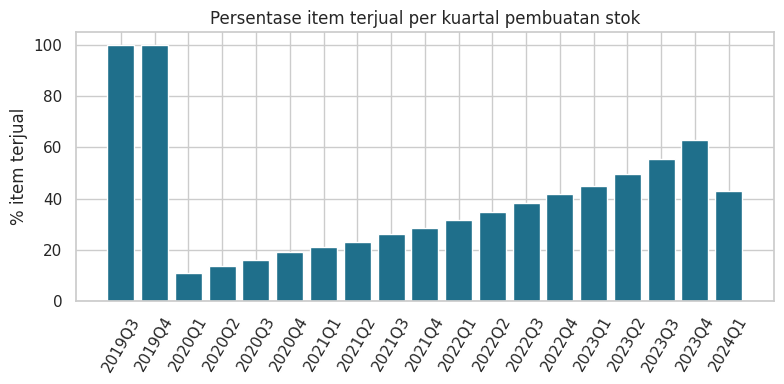

              size   mean
created_at               
2018            36  1.000
2019          4300  1.000
2020         90160  0.151
2021        101646  0.248
2022        120230  0.369
2023        145761  0.531


In [6]:
# 1. Sell-through per kuartal pembuatan stok (seluruh data, termasuk yang censored)
q = df.groupby(df.created_at.dt.tz_localize(None).dt.to_period('Q').astype(str)).is_sold.agg(['size','mean']); q = q[q['size']>=1000]
fig,ax=plt.subplots(figsize=(8,4)); ax.bar(q.index,q['mean']*100,color='#1f6f8b'); ax.set_ylabel('% item terjual'); ax.set_title('Persentase item terjual per kuartal pembuatan stok')
plt.xticks(rotation=60); plt.tight_layout(); plt.show()
print(m.groupby(m.created_at.dt.year).is_sold.agg(['size','mean']).round(3))

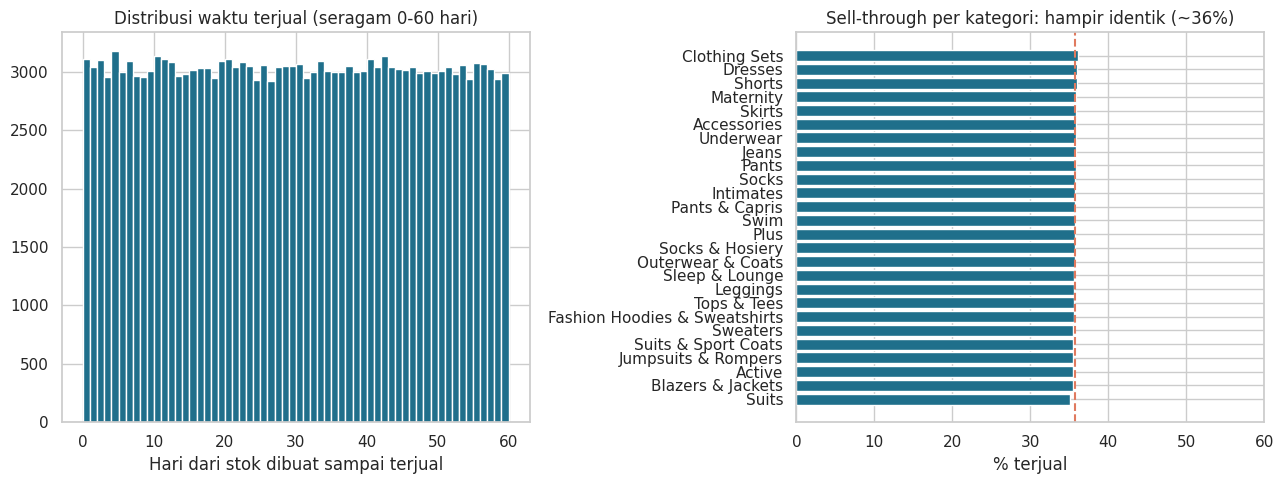

In [7]:
# 2. Waktu terjual & 3. Sell-through per kategori
fig,ax=plt.subplots(1,2,figsize=(13,5))
ax[0].hist(d.dropna(),bins=60,color='#1f6f8b'); ax[0].set_xlabel('Hari dari stok dibuat sampai terjual'); ax[0].set_title('Distribusi waktu terjual (seragam 0-60 hari)')
c=m.groupby('product_category').is_sold.mean().sort_values()*100
ax[1].barh(c.index,c.values,color='#1f6f8b'); ax[1].axvline(m.is_sold.mean()*100,color='#e07a5f',ls='--'); ax[1].set_xlim(0,60); ax[1].set_xlabel('% terjual'); ax[1].set_title('Sell-through per kategori: hampir identik (~36%)')
plt.tight_layout(); plt.show()

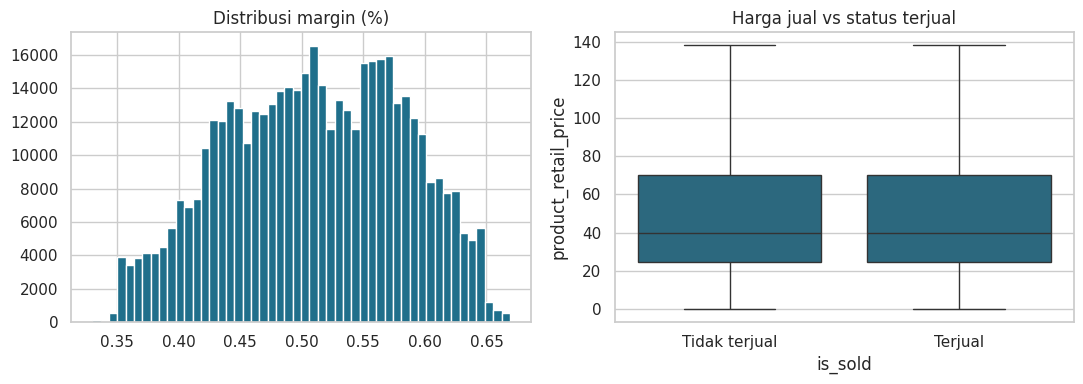

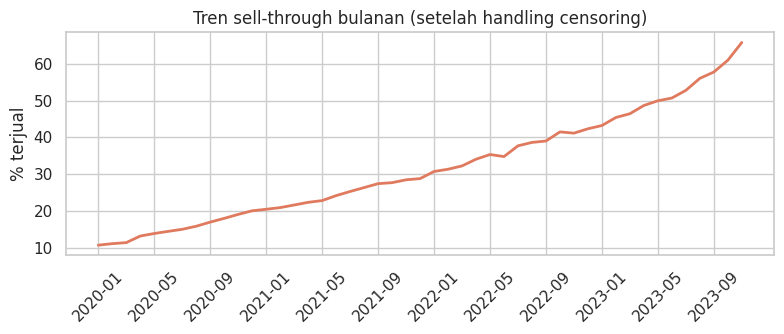

In [8]:
# 4. Margin & harga vs status terjual
mm = m.assign(margin=(m.product_retail_price-m.cost)/m.product_retail_price)
fig,ax=plt.subplots(1,2,figsize=(11,4)); ax[0].hist(mm.margin,bins=50,color='#1f6f8b'); ax[0].set_title('Distribusi margin (%)')
sns.boxplot(data=mm,x='is_sold',y='product_retail_price',ax=ax[1],color='#1f6f8b',showfliers=False); ax[1].set_title('Harga jual vs status terjual'); ax[1].set_xticklabels(['Tidak terjual','Terjual'])
plt.tight_layout(); plt.show()
# 5. Tren bulanan
mo=m.groupby(m.created_at.dt.tz_localize(None).dt.to_period('M').astype(str)).is_sold.mean().iloc[14:]
fig,ax=plt.subplots(figsize=(8,3.5)); ax.plot(mo.index,mo.values*100,color='#e07a5f',lw=2); ax.set_xticks(range(0,len(mo),4)); ax.set_xticklabels(mo.index[::4],rotation=45); ax.set_ylabel('% terjual'); ax.set_title('Tren sell-through bulanan (setelah handling censoring)')
plt.tight_layout(); plt.show()

**Insight**
1. Stok 2018–2019 (4.336 unit, <1%) **100% terjual** — patahan struktural pada Jan 2020 yang tampak seperti artefak data. Mulai 2020 sell-through naik: ±15% (2020) → 25% → 37% → 53% (2023); kuartal terakhir 63%. Pola waktu ini sangat kuat. (Kuartal paling akhir di grafik turun karena censoring.)
2. Waktu terjual seragam 0–60 hari → tidak ada "produk cepat laku" vs "lambat laku".
3. Kategori, departemen, DC: sell-through ≈ 37% di semua grup.
4. Margin 33–67% per produk; harga tidak membedakan item terjual vs tidak.

In [9]:
from scipy.stats import chi2_contingency
for c in ['product_category','product_department','product_distribution_center_id']:
    chi,p,_,_ = chi2_contingency(pd.crosstab(m[c], m.is_sold)); print(f'{c:35s} chi2={chi:9.1f} p={p:.4f}')
print('\nKorelasi dengan is_sold:'); print(mm[['cost','product_retail_price','margin','is_sold']].corr()['is_sold'].round(4))

product_category                    chi2=      4.6 p=1.0000
product_department                  chi2=      0.1 p=0.7924
product_distribution_center_id      chi2=      1.4 p=0.9979

Korelasi dengan is_sold:
cost                   -0.0004
product_retail_price   -0.0004
margin                  0.0006
is_sold                 1.0000
Name: is_sold, dtype: float64


Dengan n sangat besar, uji chi-square bisa signifikan pada efek sangat kecil; yang relevan adalah **ukuran efek** (selisih sell-through antar grup <1 poin persen).

## Tahap 3b — Model Machine Learning Dasar
Split holdout 20% **per `product_id`** (produk yang sama tidak muncul di train & test); CV memakai `GroupKFold`.

In [10]:
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, f1_score, precision_score, recall_score, brier_score_loss, roc_curve

X, y, g = m[RAW], m['is_sold'], m['product_id']
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, g))
Xtr, Xte, ytr, yte, gtr = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te], g.iloc[tr]
print('train', len(Xtr), '| holdout', len(Xte))

def prep(k):
    if k == 'lin': return ColumnTransformer([('n',StandardScaler(),NUM_COLS),('c',OneHotEncoder(handle_unknown='ignore',min_frequency=20),CAT_COLS)])
    return ColumnTransformer([('n','passthrough',NUM_COLS),('c',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1),CAT_COLS)])
models = {'Logistic Regression':(LogisticRegression(max_iter=300),'lin'),
 'Decision Tree':(DecisionTreeClassifier(max_depth=6,min_samples_leaf=200,random_state=0),'tree'),
 'Random Forest':(RandomForestClassifier(n_estimators=60,max_depth=10,min_samples_leaf=100,n_jobs=1,random_state=0),'tree'),
 'HistGradientBoosting':(HistGradientBoostingClassifier(max_iter=200,learning_rate=0.08,max_leaf_nodes=31,l2_regularization=1.0,random_state=0),'tree')}
sub = Xtr.sample(min(100000, len(Xtr)), random_state=1).index; Xs, ys, gs = Xtr.loc[sub], ytr.loc[sub], gtr.loc[sub]   # sampel utk CV (hemat waktu)
rows = []
for n,(clf,k) in models.items():
    mk = lambda: Pipeline([('fb',FeatureBuilder()),('pre',prep(k)),('clf',clf)])
    cv = [roc_auc_score(ys.iloc[b], mk().fit(Xs.iloc[a],ys.iloc[a]).predict_proba(Xs.iloc[b])[:,1]) for a,b in GroupKFold(3).split(Xs,ys,gs)]
    p = mk().fit(Xs,ys).predict_proba(Xte)[:,1]
    rows.append(dict(model=n, cv_auc=np.mean(cv), cv_std=np.std(cv), test_auc=roc_auc_score(yte,p), test_pr_auc=average_precision_score(yte,p)))
pd.DataFrame(rows).round(4)

train 368486 | holdout 93647


,model,cv_auc,cv_std,test_auc,test_pr_auc
0,Logistic Regression,0.6668,0.0002,0.6678,0.5089
1,Decision Tree,0.6958,0.0009,0.6970,0.5483
2,Random Forest,0.6955,0.0010,0.6965,0.5559
3,HistGradientBoosting,0.6970,0.0009,0.6977,0.5600


Model non-linear (Tree/RF/HGB) ≈ 0.697; Logistic Regression ≈ 0.668 karena hubungan waktu→terjual tidak linear. Semua model hampir sama → batas performa ditentukan oleh sinyal data, bukan algoritma.

## Tahap 4 — Optimasi Model, Ablasi & Validasi
### 4a. Ablasi fitur dan uji temporal

In [11]:
def pipe(num=NUM_COLS, cat=CAT_COLS, **kw):
    pre = ColumnTransformer([('n','passthrough',num),('c',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1),cat)])
    return Pipeline([('fb',FeatureBuilder()),('pre',pre),('clf',HistGradientBoostingClassifier(random_state=0, **kw))])

sets = {'Hanya waktu (t_days)':(['t_days'],[]), 'Waktu + musim':(['t_days','month_sin','month_cos','dow'],[]),
        'Tanpa waktu (harga/kategori/brand/DC)':(['log_price','log_cost','margin_pct','margin_abs'],CAT_COLS), 'Semua fitur':(NUM_COLS,CAT_COLS)}
ablation = {k: roc_auc_score(yte, pipe(n,c,max_iter=150,learning_rate=0.08).fit(Xtr,ytr).predict_proba(Xte)[:,1]) for k,(n,c) in sets.items()}
print('Ablasi AUC:'); print(pd.Series(ablation).round(4))

# Uji temporal: latih < 2023-06, uji sesudahnya (apakah model bisa mengekstrapolasi waktu?)
tm = (m.created_at < '2023-06-01').values
tmp = pipe(max_iter=150,learning_rate=0.08).fit(X[tm], y[tm]); temporal_auc = roc_auc_score(y[~tm], tmp.predict_proba(X[~tm])[:,1])
print('\nUji temporal AUC:', round(temporal_auc,4))

Ablasi AUC:
Hanya waktu (t_days)                     0.6965
Waktu + musim                            0.6993
Tanpa waktu (harga/kategori/brand/DC)    0.4997
Semua fitur                              0.6986
dtype: float64



Uji temporal AUC: 0.4979


### 4b. Hyperparameter tuning (RandomizedSearchCV + GroupKFold) dan model final

In [12]:
sub2 = Xtr.sample(min(120000, len(Xtr)), random_state=2).index
params = {'clf__learning_rate':[0.03,0.05,0.08,0.12],'clf__max_iter':[150,250,350],'clf__max_leaf_nodes':[15,31,63],
          'clf__min_samples_leaf':[20,100,300],'clf__l2_regularization':[0,1,10],'clf__max_depth':[None,6,10]}
rs = RandomizedSearchCV(pipe(), params, n_iter=10, scoring='roc_auc', cv=GroupKFold(3), random_state=0, n_jobs=1, refit=False)
rs.fit(Xtr.loc[sub2], ytr.loc[sub2], groups=gtr.loc[sub2])
best = {k.replace('clf__',''):v for k,v in rs.best_params_.items()}
print('Best params:', best); print('Best CV AUC:', round(rs.best_score_,4))

final = pipe(**best).fit(Xtr, ytr); p = final.predict_proba(Xte)[:,1]
ths = np.linspace(0.2,0.7,51); thr = float(ths[int(np.argmax([f1_score(yte,p>=t) for t in ths]))])
final_metrics = dict(auc=roc_auc_score(yte,p), pr_auc=average_precision_score(yte,p), logloss=log_loss(yte,p), brier=brier_score_loss(yte,p),
    threshold=thr, f1=f1_score(yte,p>=thr), precision=precision_score(yte,p>=thr), recall=recall_score(yte,p>=thr), base_rate=yte.mean())
print({k:round(float(v),4) for k,v in final_metrics.items()})

Best params: {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 150, 'max_depth': 10, 'learning_rate': 0.03, 'l2_regularization': 1}
Best CV AUC: 0.696


{'auc': 0.6987, 'pr_auc': 0.5613, 'logloss': 0.5905, 'brier': 0.2031, 'threshold': 0.29, 'f1': 0.5795, 'precision': 0.4634, 'recall': 0.773, 'base_rate': 0.3569}


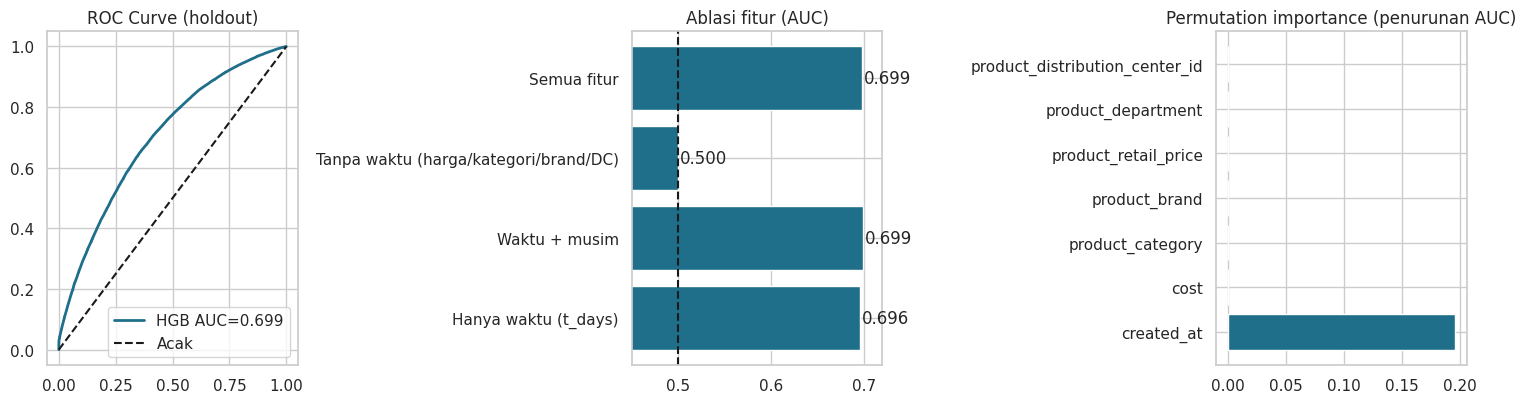

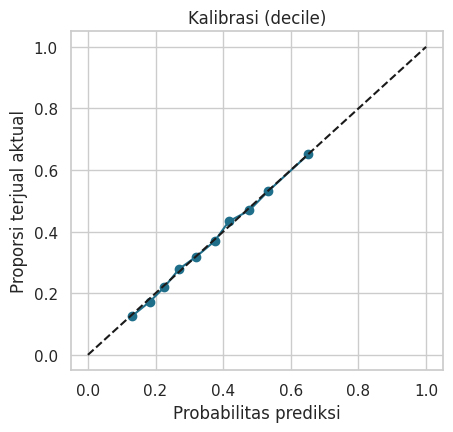

In [13]:
# Permutation importance (penurunan AUC) per kolom mentah
idx = Xte.sample(min(15000, len(Xte)), random_state=0).index; Xi, yi = Xte.loc[idx], yte.loc[idx]
base = roc_auc_score(yi, final.predict_proba(Xi)[:,1]); rng = np.random.RandomState(0); imp = {}
for col in RAW:
    Xp = Xi.copy(); Xp[col] = rng.permutation(Xp[col].values); imp[col] = base - roc_auc_score(yi, final.predict_proba(Xp)[:,1])
fpr,tpr,_ = roc_curve(yte,p); fig,ax = plt.subplots(1,3,figsize=(15,4.2))
ax[0].plot(fpr,tpr,color='#1f6f8b',lw=2,label=f"HGB AUC={final_metrics['auc']:.3f}"); ax[0].plot([0,1],[0,1],'k--',label='Acak'); ax[0].legend(); ax[0].set_title('ROC Curve (holdout)')
ax[1].barh(list(ablation.keys()),list(ablation.values()),color='#1f6f8b'); ax[1].axvline(.5,color='k',ls='--'); ax[1].set_xlim(.45,.72); ax[1].set_title('Ablasi fitur (AUC)')
for i,v in enumerate(ablation.values()): ax[1].text(v+.002,i,f'{v:.3f}',va='center')
ax[2].barh(list(imp.keys()),list(imp.values()),color='#1f6f8b'); ax[2].set_title('Permutation importance (penurunan AUC)')
plt.tight_layout(); plt.show()
cal = pd.DataFrame({'p':p,'y':yte.values}).groupby(pd.qcut(p,10,duplicates='drop')).mean()
fig,ax = plt.subplots(figsize=(4.8,4.4)); ax.plot(cal.p,cal.y,'o-',color='#1f6f8b'); ax.plot([0,1],[0,1],'k--'); ax.set_xlabel('Probabilitas prediksi'); ax.set_ylabel('Proporsi terjual aktual'); ax.set_title('Kalibrasi (decile)'); plt.show()

### 4c. Deep Learning (TensorFlow/Keras)
MLP kecil pada fitur yang sama (one-hot + scaling), dilatih pada sampel 80 ribu baris (keterbatasan komputasi), dengan EarlyStopping pada val-AUC.

I0000 00:00:1792810105.221288    1339 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792810106.401055    1339 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


{'auc': 0.6926, 'pr_auc': 0.5505, 'logloss': 0.5964, 'epochs': 39, 'params': 6209, 'input_dim': 63}


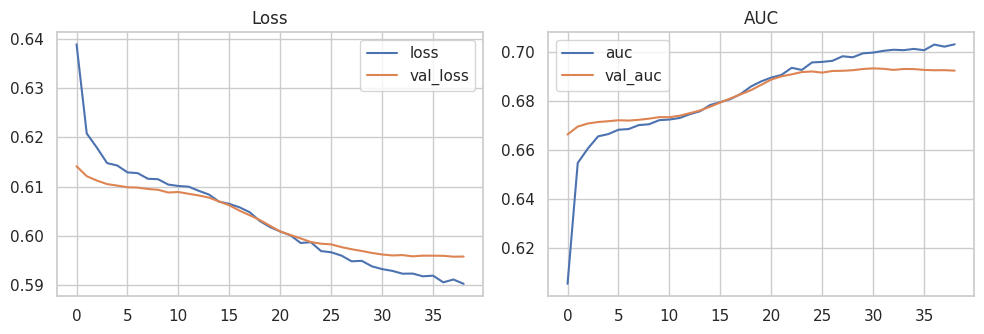

In [14]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL']='3'; os.environ['TF_NUM_INTRAOP_THREADS']='1'; os.environ['TF_NUM_INTEROP_THREADS']='1'
import tensorflow as tf
tf.random.set_seed(0); np.random.seed(0)
tr_s = np.random.RandomState(0).choice(tr, min(80000, len(tr)), replace=False)
pre_dl = Pipeline([('fb',FeatureBuilder()),('ct',ColumnTransformer([('n',StandardScaler(),NUM_COLS),('c',OneHotEncoder(handle_unknown='ignore',min_frequency=500,sparse_output=False),CAT_COLS)]))])
Xd_tr = pre_dl.fit_transform(X.iloc[tr_s]).astype('float32'); Xd_te = pre_dl.transform(X.iloc[te]).astype('float32')
yd_tr, yd_te = y.iloc[tr_s].values, y.iloc[te].values
mlp = tf.keras.Sequential([tf.keras.layers.Input((Xd_tr.shape[1],)), tf.keras.layers.Dense(64,activation='relu'), tf.keras.layers.Dropout(0.2),
                           tf.keras.layers.Dense(32,activation='relu'), tf.keras.layers.Dropout(0.2), tf.keras.layers.Dense(1,activation='sigmoid')])
mlp.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=[tf.keras.metrics.AUC(name='auc')])
hist = mlp.fit(Xd_tr, yd_tr, validation_split=0.15, epochs=80, batch_size=1024, verbose=0,
               callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=8, restore_best_weights=True)])
pd_ = mlp.predict(Xd_te, batch_size=4096, verbose=0).ravel()
dl = dict(auc=roc_auc_score(yd_te,pd_), pr_auc=average_precision_score(yd_te,pd_), logloss=log_loss(yd_te,pd_), epochs=len(hist.history['loss']), params=mlp.count_params(), input_dim=Xd_tr.shape[1])
print({k:(round(v,4) if isinstance(v,float) else v) for k,v in dl.items()})
h = pd.DataFrame(hist.history); fig,ax=plt.subplots(1,2,figsize=(10,3.5))
h[['loss','val_loss']].plot(ax=ax[0],title='Loss'); h[['auc','val_auc']].plot(ax=ax[1],title='AUC'); plt.tight_layout(); plt.show()

### Evaluasi & temuan penting
- **Ablasi:** hanya `t_days` → AUC ≈ 0.696; tanpa waktu → **0.500** (acak). Seluruh sinyal ada pada waktu pembuatan stok.
- **Uji temporal** (latih ≤ Mei 2023, uji sesudahnya): AUC ≈ **0.498** → model tidak mengekstrapolasi tren; butuh monitoring dan retraining berkala.
- **Model akhir:** HistGradientBoosting (AUC ≈ 0.699) sedikit di atas MLP Keras (≈ 0.693) dengan fitur yang sama; pada data tabular dengan satu fitur dominan, deep learning tidak memberi keunggulan.
- **Threshold** ≈ 0.29 (maks. F1) → recall tinggi, precision sedang (base rate 0.357): cocok untuk *screening* dead-stock, bukan keputusan otomatis.

## Tahap 4d — Deployment & MLOps
Model final dan aplikasi ada di repo proyek ini:
- `app.py` — Streamlit (prediksi interaktif + insight + info model); `Dockerfile` + `requirements.txt`.
- Satu `Pipeline` (FeatureBuilder + encoder + model) tersimpan sebagai `model/model.joblib` → tidak ada training-serving skew.
- Jalankan: `docker build -t sellthrough . && docker run -p 8501:8501 sellthrough`
- Monitoring: bandingkan rata-rata probabilitas vs sell-through aktual per bulan; retrain bila AUC bulanan < 0.65.

## Rekomendasi bisnis
1. Jangan menyusun strategi per kategori/brand/DC berdasarkan sell-through: datanya tidak membedakan. Fokus pada faktor lain (promo, stok per ukuran, harga kompetitor) yang belum ada di dataset.
2. Item tidak terjual setelah 60 hari praktis tidak akan terjual → jadwalkan diskon/likuidasi di hari ke-45–60.
3. Tambah data (promosi, trafik, stok per SKU/ukuran, musim) untuk menaikkan AUC melampaui 0.70.
4. Pakai model sebagai alat screening dengan monitoring drift, bukan prediksi masa depan jangka panjang.